In [216]:
import pandas as pd
import matplotlib.pyplot as plt


# # Load dataframe (Titanic)

In [217]:
df = pd.read_csv("Titanic-Dataset.csv")

# # Load dataframe (Train)

In [218]:
# df1 = pd.read_csv('train.csv')
# df1.isna().sum()
# df1.shape

# Exploratory Data

In [219]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [220]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [221]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [222]:
df.shape

(891, 12)

In [223]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [224]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [225]:
df.shape

(891, 12)

# # Cleaning Data

In [244]:
df.fillna({'Age': df['Age'].median(), 'Embarked': df['Embarked'].mode()[0]}, inplace=True)

df['Age'].isna().sum()
df['Embarked'].isna().sum()
df['Embarked'].describe()

count     891
unique      3
top         S
freq      646
Name: Embarked, dtype: object

In [227]:
# useless data
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])


# # Analyze Data

In [228]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


# Feature Engineering 

In [229]:
FamilySize = df['SibSp'] + df['Parch'] + 1
df['FamilySize'] = FamilySize
df['FamilySize']

0      2
1      2
2      1
3      2
4      1
      ..
886    1
887    1
888    4
889    1
890    1
Name: FamilySize, Length: 891, dtype: int64

In [230]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 19, 60, 100],
    labels=['child', 'teen', 'adult', 'senior']
)


In [232]:
df.groupby('AgeGroup', observed=True)['Survived'].mean()

AgeGroup
child     0.579710
teen      0.410526
adult     0.365957
senior    0.227273
Name: Survived, dtype: float64

# Univariate Analysis

In [233]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [234]:
df.groupby('Sex')['Pclass'].value_counts()

Sex     Pclass
female  3         144
        1          94
        2          76
male    3         347
        1         122
        2         108
Name: count, dtype: int64

# Bivariate Analysis

In [251]:
df.groupby(['Sex', 'Pclass', 'AgeGroup', 'Embarked'])['Survived'].value_counts()
survival_by_sex = df.groupby('Sex')['Survived'].mean() * 100
survival_by_sex

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

In [237]:
df.groupby('Sex')['Survived'].agg(['count', 'sum', 'mean'])

,count,sum,mean
Sex,,,
female,314,233,0.742038
male,577,109,0.188908


# Correlation Analysis

In [238]:
corr = df.corr(numeric_only=True)
corr

,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize
Survived,1.000000,-0.338481,-0.064910,-0.035322,0.081629,0.257307,0.016639
Pclass,-0.338481,1.000000,-0.339898,0.083081,0.018443,-0.549500,0.065997
Age,-0.064910,-0.339898,1.000000,-0.233296,-0.172482,0.096688,-0.245619
SibSp,-0.035322,0.083081,-0.233296,1.000000,0.414838,0.159651,0.890712
Parch,0.081629,0.018443,-0.172482,0.414838,1.000000,0.216225,0.783111
Fare,0.257307,-0.549500,0.096688,0.159651,0.216225,1.000000,0.217138
FamilySize,0.016639,0.065997,-0.245619,0.890712,0.783111,0.217138,1.000000


In [252]:
heat_map = df.corr(numeric_only=True)['Survived'].sort_values()
heat_map

Pclass       -0.338481
Age          -0.064910
SibSp        -0.035322
FamilySize    0.016639
Parch         0.081629
Fare          0.257307
Survived      1.000000
Name: Survived, dtype: float64

# Visulization

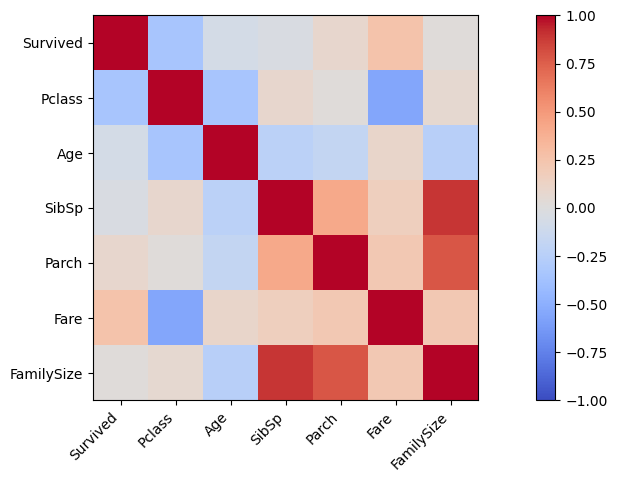

In [ ]:
fig, ax = plt.subplots(figsize=(15, 5))
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

# axes range fix
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))

# labeling 
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.columns)

fig.colorbar(image)

plt.show()

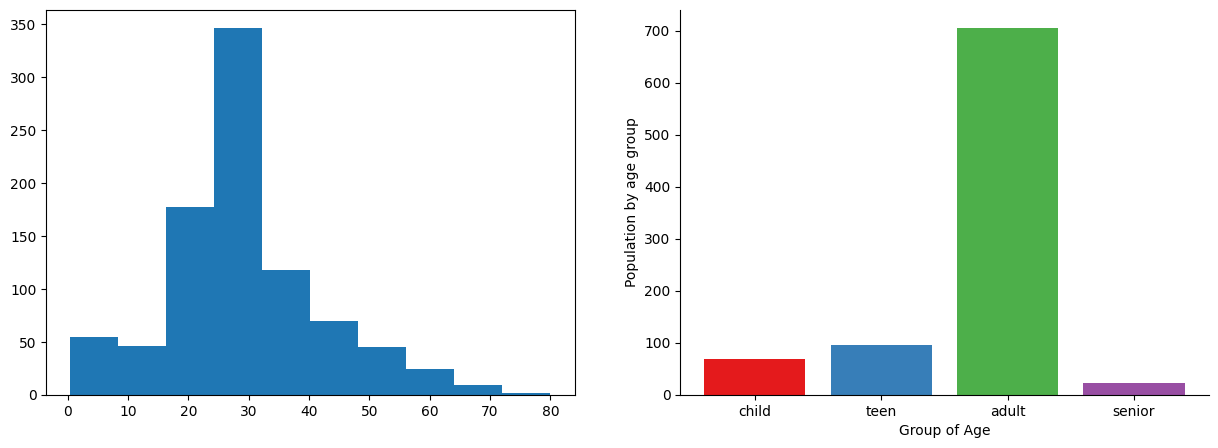

In [241]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax1 = axes[0]
ax2 = axes[1]

# Histogram: Age
ax1.hist(df['Age'], bins=10)


# Bar chart: AgeGroup
colors = plt.cm.Set1.colors
level = ['child', 'teen', 'adult', 'senior']
age_group = df['AgeGroup'].value_counts().sort_index().reindex(level, fill_value=0)
ax2.bar(age_group.index, age_group.values, color=colors)

ax2.spines[['top', 'right']].set_visible(False)
ax2.set_xlabel('Group of Age')
ax2.set_ylabel('Population by age group')


plt.show()